# Parameter-Efficient Fine-Tuning of Qwen2.5-VL-3B-Instruct for SRS Ambiguity Detection

**Abstract & Overview:**
This experimental notebook investigates domain-adapted Vision-Language Models (VLMs) for Software Requirements Specifications (SRS) ambiguity classification. We adapt `Qwen/Qwen2.5-VL-3B-Instruct` using 4-bit QLoRA on the QuRE dataset (2,109 deduplicated requirements) across three random seeds (42, 123, 456).

We evaluate whether multimodal model fine-tuning yields superior representation and sensitivity over text-only LLMs on software engineering artifacts. Standard ROC-AUC and PR-AUC are computed directly from continuous next-token logits.

## 1. Environment Setup and Dependency Installation
Installs HuggingFace Transformers, PEFT, TRL, BitsAndBytes, and Scikit-Learn configured for multimodal QLoRA fine-tuning.

In [6]:
!pip install -q transformers>=4.45.0
!pip install -q peft>=0.12.0              # LoRA / QLoRA
!pip install -q trl>=0.11.0               # SFTTrainer
!pip install -q bitsandbytes>=0.43.0      # 4-bit quant
!pip install -q accelerate>=0.34.0
!pip install -q qwen-vl-utils             # Qwen2.5-VL utils
!pip install -q datasets
!pip install -q scikit-learn
!pip install -q matplotlib seaborn
!pip install -q pandas numpy

import os, warnings
warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

print('✅ Installation complete!')


✅ Installation complete!


## 2. Dataset Ingestion and Standardization
Loads and inspects the QuRE dataset with standardized text cleaning to ensure experimental parity.


[Dataset] Loaded: data/QuRE.csv
   Total samples: 2109
   Columns      : ['id', 'requirement', 'defect', 'weak_word']

Class Distribution:
defect
ok        1486
defect     623
Name: count, dtype: int64


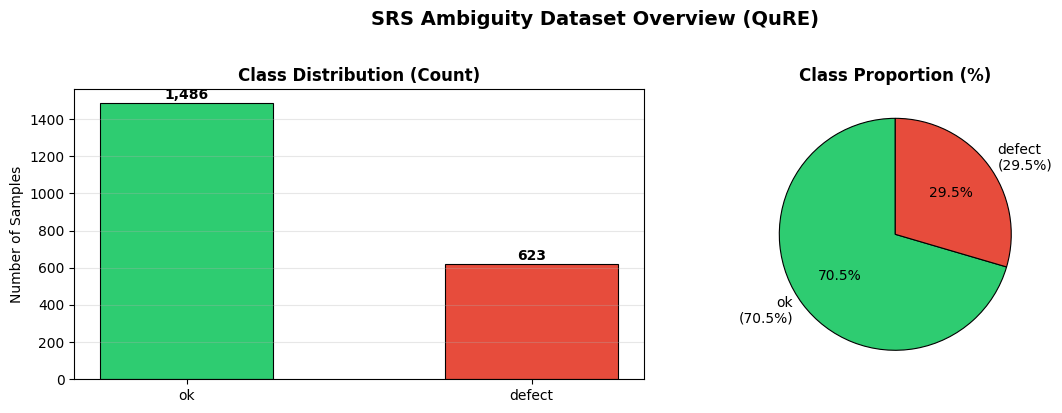

In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

candidate_paths = [
    'data/QuRE.csv',
    '../data/QuRE.csv',
    'QuRE.csv',
    'data/datasetRE.csv',
    '../data/datasetRE.csv',
    'datasetRE.csv'
]

filename = None
for candidate in candidate_paths:
    if os.path.exists(candidate):
        filename = candidate
        break

if filename is None:
    try:
        url = 'https://raw.githubusercontent.com/HoangKhoi1704/VLM-in-ambiguity-RE/main/data/QuRE.csv'
        print('Fetching dataset from repository: ' + url)
        df_fetched = pd.read_csv(url)
        os.makedirs('data', exist_ok=True)
        filename = 'data/QuRE.csv'
        df_fetched.to_csv(filename, index=False)
    except Exception:
        pass

if filename is None:
    try:
        from google.colab import files
        print('Upload QuRE.csv or datasetRE.csv:')
        uploaded = files.upload()
        filename = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError('QuRE.csv or datasetRE.csv not found in directory!')

df = pd.read_csv(filename)
print(f'\n[Dataset] Loaded: {filename}')
print(f'   Total samples: {len(df)}')
print(f'   Columns      : {df.columns.tolist()}')
print(f'\nClass Distribution:')
print(df['defect'].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

label_order = ['ok', 'defect']
counts = df['defect'].value_counts().reindex(label_order, fill_value=0)
colors = ['#2ecc71', '#e74c3c']

axes[0].bar(label_order, counts, color=colors, width=0.5, edgecolor='black', linewidth=0.8)
axes[0].set_title('Class Distribution (Count)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Samples')
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(counts):
    axes[0].text(i, v + 20, f'{v:,}', ha='center', fontweight='bold')

pcts = [counts['ok'] / len(df) * 100, counts['defect'] / len(df) * 100]
axes[1].pie(
    pcts,
    labels=[f'ok\n({pcts[0]:.1f}%)', f'defect\n({pcts[1]:.1f}%)'],
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.8}
)
axes[1].set_title('Class Proportion (%)', fontsize=12, fontweight='bold')

plt.suptitle('SRS Ambiguity Dataset Overview (QuRE)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 3. Stratified Dataset Partitioning
Constructs stratified 80/10/10 splits across configurable random seeds (42, 123, 456) preserving the ~70.2% `ok` : ~29.8% `defect` distribution.

In [8]:
from sklearn.model_selection import train_test_split

RANDOM_SEED = 456
print(f'Using RANDOM_SEED = {RANDOM_SEED}')

df_trainval, df_test = train_test_split(
    df, test_size=0.10, random_state=RANDOM_SEED, stratify=df['defect']
)

df_train, df_val = train_test_split(
    df_trainval, test_size=0.1111, random_state=RANDOM_SEED, stratify=df_trainval['defect']
)

df_train = df_train.reset_index(drop=True)
df_val   = df_val.reset_index(drop=True)
df_test  = df_test.reset_index(drop=True)

print('Split summary:')
print(f'   Train : {len(df_train):4d} samples | ok={sum(df_train["defect"]=="ok")} | defect={sum(df_train["defect"]=="defect")}')
print(f'   Val   : {len(df_val):4d} samples | ok={sum(df_val["defect"]=="ok")} | defect={sum(df_val["defect"]=="defect")}')
print(f'   Test  : {len(df_test):4d} samples | ok={sum(df_test["defect"]=="ok")} | defect={sum(df_test["defect"]=="defect")}')
print(f'   Total : {len(df_train)+len(df_val)+len(df_test):4d} samples')


Using RANDOM_SEED = 456
Split summary:
   Train : 1687 samples | ok=1188 | defect=499
   Val   :  211 samples | ok=149 | defect=62
   Test  :  211 samples | ok=149 | defect=62
   Total : 2109 samples


## 4. Prompt Engineering and Chat Template Formulation
Configures instruction templates mapping requirement statements to single-token supervisory targets.

In [9]:
import re
from typing import Optional

VALID_LABELS  = {"ok", "defect"}
MAX_REQ_CHARS = 800

SYSTEM_PROMPT = """You are an expert SRS (Software Requirements Specification) analyst.
Your task is to classify whether a given requirement contains a defect (ambiguity, vagueness, or incompleteness).
Respond with ONLY one word: either 'ok' or 'defect'. No explanation."""

def clean_requirement(text: str) -> str:
    """Normalize whitespace and truncate if length exceeds maximum limit."""
    text = re.sub(r'\s+', ' ', str(text)).strip()
    if len(text) > MAX_REQ_CHARS:
        print(f"⚠️  Requirement truncated: {len(text)} → {MAX_REQ_CHARS} characters")
        text = text[:MAX_REQ_CHARS] + "..."
    return text

def build_prompt(requirement: str, label: str = None) -> list:
    """
    Format prompt following Qwen2.5 chat template.
    - Training: includes label (answer)
    - Inference: prompt only without label
    """
    if label is not None:
        label = label.strip().lower()
        if label not in VALID_LABELS:
            raise ValueError(f"Invalid label: {label!r}. Accepted: {VALID_LABELS}")

    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user",   "content": f"Requirement: {clean_requirement(requirement)}"}
    ]
    if label is not None:
        messages.append({"role": "assistant", "content": label})
    return messages

sample_req = df_train.iloc[0]['requirement']
sample_lbl = df_train.iloc[0]['defect']
print('Example prompt (training):')
print(f'   Requirement : {sample_req[:80]}...')
print(f'   Label       : {sample_lbl}')
print()
for msg in build_prompt(sample_req, sample_lbl):
    print(f'[{msg["role"].upper()}] {msg["content"][:100]}')


Example prompt (training):
   Requirement : The contents of the OCM_A1 message are used for activation of the restraint feat...
   Label       : ok

[SYSTEM] You are an expert SRS (Software Requirements Specification) analyst.
Your task is to classify whethe
[USER] Requirement: The contents of the OCM_A1 message are used for activation of the restraint features as
[ASSISTANT] ok


## 5. Vision-Language Model Initialization with 4-bit QLoRA
Initializes `Qwen/Qwen2.5-VL-3B-Instruct` in 4-bit NormalFloat quantization with LoRA adapter configuration ($r=16, \alpha=32$).

In [10]:
import torch
from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor,
    BitsAndBytesConfig
)
from peft import LoraConfig, get_peft_model, TaskType, prepare_model_for_kbit_training

assert torch.cuda.is_available(), '❌ GPU not detected! Please select GPU (e.g. T4) in Runtime.'
vram_total = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f'️  GPU  : {torch.cuda.get_device_name(0)}')
print(f'VRAM : {vram_total:.1f} GB')

MODEL_ID = 'Qwen/Qwen2.5-VL-3B-Instruct'

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

print(f'\nLoading model: {MODEL_ID}')
print('⏳ Initial download (~7GB) may take 3-5 minutes...\n')

processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    padding_side='right'
)

if processor.tokenizer.pad_token is None:
    processor.tokenizer.pad_token = processor.tokenizer.eos_token

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map='auto',
    trust_remote_code=True,
    torch_dtype=torch.float16,
)

model = prepare_model_for_kbit_training(model)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=[
        'q_proj', 'k_proj', 'v_proj', 'o_proj',
        'gate_proj', 'up_proj', 'down_proj'
    ],
    lora_dropout=0.05,
    bias='none',
    task_type=TaskType.CAUSAL_LM,
)

model = get_peft_model(model, lora_config)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
vram_used = torch.cuda.memory_allocated() / 1e9

print('✅ Model is ready!')
print(f'   Trainable params : {trainable:,} ({100*trainable/total:.2f}%)')
print(f'   Total params     : {total:,}')
print(f'   VRAM currently in use: {vram_used:.2f} GB / {vram_total:.1f} GB')


️  GPU  : Tesla T4
VRAM : 15.6 GB

Loading model: Qwen/Qwen2.5-VL-3B-Instruct
⏳ Initial download (~7GB) may take 3-5 minutes...



Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

✅ Model is ready!
   Trainable params : 37,152,768 (1.79%)
   Total params     : 2,071,177,216
   VRAM currently in use: 4.98 GB / 15.6 GB


## 6. Dataset Tokenization and Loss Masking
Tokenizes multimodal input structures, masking non-target tokens to restrict gradient backpropagation to the classification token.

In [11]:
from datasets import Dataset

MAX_LENGTH = 256

def tokenize_sample(example):
    """Tokenize sample and mask prompt tokens to exclude them from cross-entropy loss"""
    messages = build_prompt(example['requirement'], example['defect'])

    full_text = processor.tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )

    prompt_messages = messages[:-1]
    prompt_text = processor.tokenizer.apply_chat_template(
        prompt_messages,
        tokenize=False,
        add_generation_prompt=True
    )

    tokenized_full = processor.tokenizer(
        full_text,
        max_length=MAX_LENGTH,
        padding='max_length',
        truncation=True,
        return_tensors=None
    )

    tokenized_prompt = processor.tokenizer(
        prompt_text,
        max_length=MAX_LENGTH,
        truncation=True,
        return_tensors=None
    )

    prompt_len = len(tokenized_prompt['input_ids'])

    labels = tokenized_full['input_ids'].copy()

    for i in range(min(prompt_len, MAX_LENGTH)):
        labels[i] = -100

    for i in range(len(labels)):
        if tokenized_full['input_ids'][i] == processor.tokenizer.pad_token_id:
            labels[i] = -100

    tokenized_full['labels'] = labels
    return tokenized_full

print('Tokenizing dataset with prompt masking...')

hf_train = Dataset.from_pandas(df_train[['requirement','defect']])
hf_val   = Dataset.from_pandas(df_val[['requirement','defect']])
hf_test  = Dataset.from_pandas(df_test[['requirement','defect']])

hf_train = hf_train.map(tokenize_sample, batched=False, desc='Tokenizing train')
hf_val   = hf_val.map(tokenize_sample,   batched=False, desc='Tokenizing val')

keep_cols = ['input_ids', 'attention_mask', 'labels']
hf_train = hf_train.select_columns(keep_cols)
hf_val   = hf_val.select_columns(keep_cols)

print(f'\n✅ Prompt masking configured successfully!')
print(f'   Loss is now computed exclusively on the target label token (ok/defect).')


Tokenizing dataset with prompt masking...


Tokenizing train:   0%|          | 0/1687 [00:00<?, ? examples/s]

Tokenizing val:   0%|          | 0/211 [00:00<?, ? examples/s]


✅ Prompt masking configured successfully!
   Loss is now computed exclusively on the target label token (ok/defect).


## 7. Model Optimization and Training Protocol
Executes SFTTrainer with gradient accumulation and evaluation loss monitoring to select the optimal model checkpoint.

In [12]:
from transformers import TrainingArguments, DataCollatorForSeq2Seq, Trainer
import json

EPOCHS        = 4
BATCH_SIZE    = 4
GRAD_ACCUM    = 4
LR            = 2e-4
WARMUP_RATIO  = 0.05
OUTPUT_DIR    = f'./srs_vlm_finetune_seed_{RANDOM_SEED}'

training_args = TrainingArguments(
    seed=RANDOM_SEED,
    data_seed=RANDOM_SEED,
    output_dir=OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR,
    warmup_steps=WARMUP_RATIO,
    lr_scheduler_type='cosine',
    fp16=True,
    optim='paged_adamw_8bit',
    logging_steps=5,
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    greater_is_better=False,
    report_to='none',
    dataloader_num_workers=0,
    remove_unused_columns=False,
)

data_collator = DataCollatorForSeq2Seq(
    tokenizer=processor.tokenizer,
    model=model,
    padding=True,
    pad_to_multiple_of=8,
    label_pad_token_id=-100
)

from transformers import TrainerCallback

class HistoryCallback(TrainerCallback):
    def __init__(self):
        self.train_loss_steps = []
        self.val_loss_epochs  = []
        self.lr_history       = []

    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs:
            if 'loss' in logs:
                self.train_loss_steps.append((state.global_step, logs['loss']))
            if 'eval_loss' in logs:
                self.val_loss_epochs.append((state.epoch, logs['eval_loss']))
            if 'learning_rate' in logs:
                self.lr_history.append((state.global_step, logs['learning_rate']))

history_cb = HistoryCallback()

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=hf_train,
    eval_dataset=hf_val,
    data_collator=data_collator,
    callbacks=[history_cb],
)

print('Starting QLoRA fine-tuning pipeline...')
print(f'   Train samples  : {len(hf_train)}')
print()

train_result = trainer.train()

print('\n✅ Training completed successfully!')
print(f'   Final training loss: {train_result.training_loss:.4f}')

with open('training_history.json', 'w') as f:
    json.dump({
        'train_loss_steps': history_cb.train_loss_steps,
        'val_loss_epochs':  history_cb.val_loss_epochs,
        'lr_history':       history_cb.lr_history
    }, f)


Starting QLoRA fine-tuning pipeline...
   Train samples  : 1687



[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Epoch,Training Loss,Validation Loss
1,0.085678,0.191922
2,0.045446,0.107794
3,0.014039,0.138805
4,0.003591,0.168890



✅ Training completed successfully!
   Final training loss: 0.0802


## 8. Optimization Trajectory and Convergence Analysis
Visualizes loss convergence across training epochs, assessing stability and generalization.

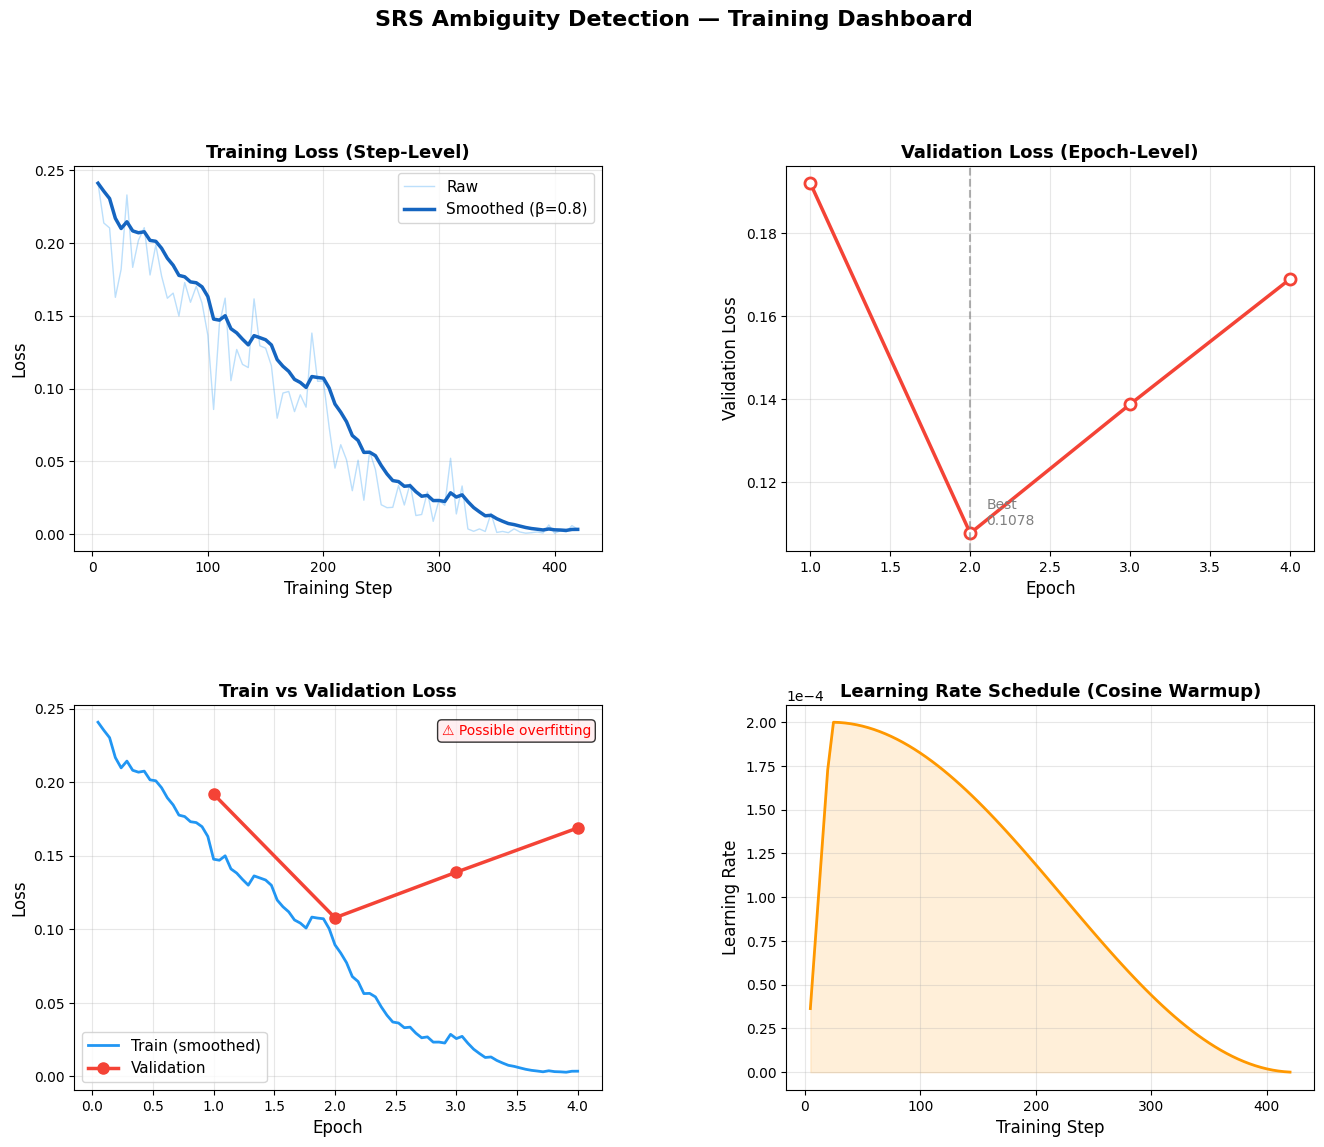

Training dashboard saved to: training_dashboard.png

Training Summary:
   Initial train loss : 0.2408
   Final train loss   : 0.0036
   Best val loss      : 0.1078  (epoch 2.0)
   Final val loss     : 0.1689


In [13]:
import json
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

with open('training_history.json') as f:
    hist = json.load(f)

train_steps  = [x[0] for x in hist['train_loss_steps']]
train_losses = [x[1] for x in hist['train_loss_steps']]
val_epochs   = [x[0] for x in hist['val_loss_epochs']]
val_losses   = [x[1] for x in hist['val_loss_epochs']]
lr_steps     = [x[0] for x in hist['lr_history']]
lr_values    = [x[1] for x in hist['lr_history']]

def smooth(values, weight=0.8):
    smoothed = []
    last = values[0]
    for v in values:
        last = last * weight + v * (1 - weight)
        smoothed.append(last)
    return smoothed

train_smooth = smooth(train_losses)

fig = plt.figure(figsize=(16, 12))
gs  = gridspec.GridSpec(2, 2, hspace=0.4, wspace=0.35)

COLORS = {'train':'#2196F3', 'val':'#F44336', 'lr':'#FF9800', 'smooth':'#1565C0'}

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(train_steps, train_losses, alpha=0.3, color=COLORS['train'], linewidth=1, label='Raw')
ax1.plot(train_steps, train_smooth, color=COLORS['smooth'], linewidth=2.5, label='Smoothed (β=0.8)')
ax1.set_xlabel('Training Step', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.set_title('Training Loss (Step-Level)', fontsize=13, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(val_epochs, val_losses, 'o-', color=COLORS['val'],
         linewidth=2.5, markersize=8, markerfacecolor='white', markeredgewidth=2)
best_idx = int(np.argmin(val_losses))
ax2.axvline(x=val_epochs[best_idx], color='gray', linestyle='--', alpha=0.6)
ax2.annotate(f'Best\n{val_losses[best_idx]:.4f}',
             xy=(val_epochs[best_idx], val_losses[best_idx]),
             xytext=(val_epochs[best_idx]+0.1, val_losses[best_idx]+0.002),
             fontsize=10, color='gray')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Validation Loss', fontsize=12)
ax2.set_title('Validation Loss (Epoch-Level)', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(gs[1, 0])
steps_per_epoch = max(train_steps) / len(val_epochs) if val_epochs else 1
train_epochs_x  = [s / steps_per_epoch for s in train_steps]
ax3.plot(train_epochs_x, train_smooth, color=COLORS['train'], linewidth=2, label='Train (smoothed)')
ax3.plot(val_epochs, val_losses, 'o-', color=COLORS['val'],
         linewidth=2.5, markersize=8, label='Validation')
ax3.set_xlabel('Epoch', fontsize=12)
ax3.set_ylabel('Loss', fontsize=12)
ax3.set_title('Train vs Validation Loss', fontsize=13, fontweight='bold')
ax3.legend(fontsize=11)
ax3.grid(True, alpha=0.3)

if len(val_losses) >= 3:
    last3_val = val_losses[-3:]
    if last3_val[-1] > last3_val[0]:
        ax3.text(0.98, 0.95, '⚠️ Possible overfitting',
                 transform=ax3.transAxes, ha='right', va='top',
                 fontsize=10, color='red',
                 bbox=dict(boxstyle='round', facecolor='#FFEBEE', alpha=0.8))

ax4 = fig.add_subplot(gs[1, 1])
if lr_steps:
    ax4.plot(lr_steps, lr_values, color=COLORS['lr'], linewidth=2)
    ax4.fill_between(lr_steps, lr_values, alpha=0.15, color=COLORS['lr'])
ax4.set_xlabel('Training Step', fontsize=12)
ax4.set_ylabel('Learning Rate', fontsize=12)
ax4.set_title('Learning Rate Schedule (Cosine Warmup)', fontsize=13, fontweight='bold')
ax4.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax4.grid(True, alpha=0.3)

fig.suptitle('SRS Ambiguity Detection — Training Dashboard', fontsize=16, fontweight='bold', y=1.01)
plt.savefig('training_dashboard.png', dpi=130, bbox_inches='tight')
plt.show()
print('Training dashboard saved to: training_dashboard.png')

print('\nTraining Summary:')
print(f'   Initial train loss : {train_losses[0]:.4f}')
print(f'   Final train loss   : {train_losses[-1]:.4f}')
print(f'   Best val loss      : {min(val_losses):.4f}  (epoch {val_epochs[best_idx]})')
print(f'   Final val loss     : {val_losses[-1]:.4f}')


## 9. Hold-Out Evaluation and Probability Extraction
Executes forward evaluation over the isolated test set to extract candidate logits and continuous posterior probabilities $P(\text{defect})$.

In [14]:
import torch
from tqdm import tqdm

model.eval()
tok = processor.tokenizer

id_ok = tok.encode('ok', add_special_tokens=False)[0]
id_defect = tok.encode('defect', add_special_tokens=False)[0]
print(f'Target Token IDs: ok={id_ok}, defect={id_defect}')

def predict(requirement: str) -> tuple[str, float]:
    """
    Predict label and extract continuous posterior probability P(defect).
    Returns:
        pred_label: 'ok' or 'defect'
        p_defect: continuous posterior probability in [0.0, 1.0]
    """
    messages = build_prompt(requirement)
    text_input = tok.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = tok(
        text_input,
        return_tensors='pt',
        truncation=True,
        max_length=256
    ).to(model.device)

    with torch.no_grad():
        outputs = model(**inputs)
        next_token_logits = outputs.logits[0, -1, :]
        logits_pair = torch.tensor([next_token_logits[id_ok], next_token_logits[id_defect]], device=model.device)
        probs = torch.softmax(logits_pair, dim=-1)

        p_defect = probs[1].item()
        pred_label = 'defect' if p_defect >= 0.5 else 'ok'
        return pred_label, p_defect

print(f'Starting inference on {len(df_test)} test samples (Seed: {RANDOM_SEED})...')
y_true = []
y_pred = []
y_scores = []

for idx, row in tqdm(df_test.iterrows(), total=len(df_test), desc='GPU Inference'):
    req = str(row['requirement'])
    true_label = str(row['defect']).strip().lower()
    pred_label, p_defect = predict(req)

    y_true.append(true_label)
    y_pred.append(pred_label)
    y_scores.append(p_defect)

df_test['predicted'] = y_pred
df_test['p_defect']  = y_scores
df_test['correct']   = df_test['defect'] == df_test['predicted']

acc_check = sum(df_test['correct']) / len(df_test)
print(f'\n✅ Inference routine completed!')
print(f'   Quick check accuracy on Test Set: {acc_check:.4f} ({acc_check*100:.2f}%)')


Target Token IDs: ok=562, defect=750
Starting inference on 211 test samples (Seed: 456)...


GPU Inference: 100%|██████████| 211/211 [00:41<00:00,  5.06it/s]


✅ Inference routine completed!
   Quick check accuracy on Test Set: 0.8483 (84.83%)


## 10. Quantitative Performance Metrics & Diagnostic Visualizations
Computes formal classification metrics (Accuracy, Balanced Accuracy, Macro F1, MCC, Standard ROC-AUC, PR-AUC) and visualization curves.

   EVALUATION REPORT — TEST SET (Seed: {RANDOM_SEED})
  Accuracy             : 0.8483  (84.83%)
  Balanced Acc (BAcc)  : 0.8079
  F1 (macro)           : 0.8137
  F1 (weighted)        : 0.8468
  MCC                  : 0.6282  (range: -1 ~ 1)
  Standard ROC-AUC     : 0.9257
  PR-AUC               : 0.8334

  Class: defect (Ambiguous)
    Precision          : 0.7586
    Recall             : 0.7097
    F1-score           : 0.7333

  Class: ok (Unambiguous)
    Precision          : 0.8824
    Recall             : 0.9060
    F1-score           : 0.8940


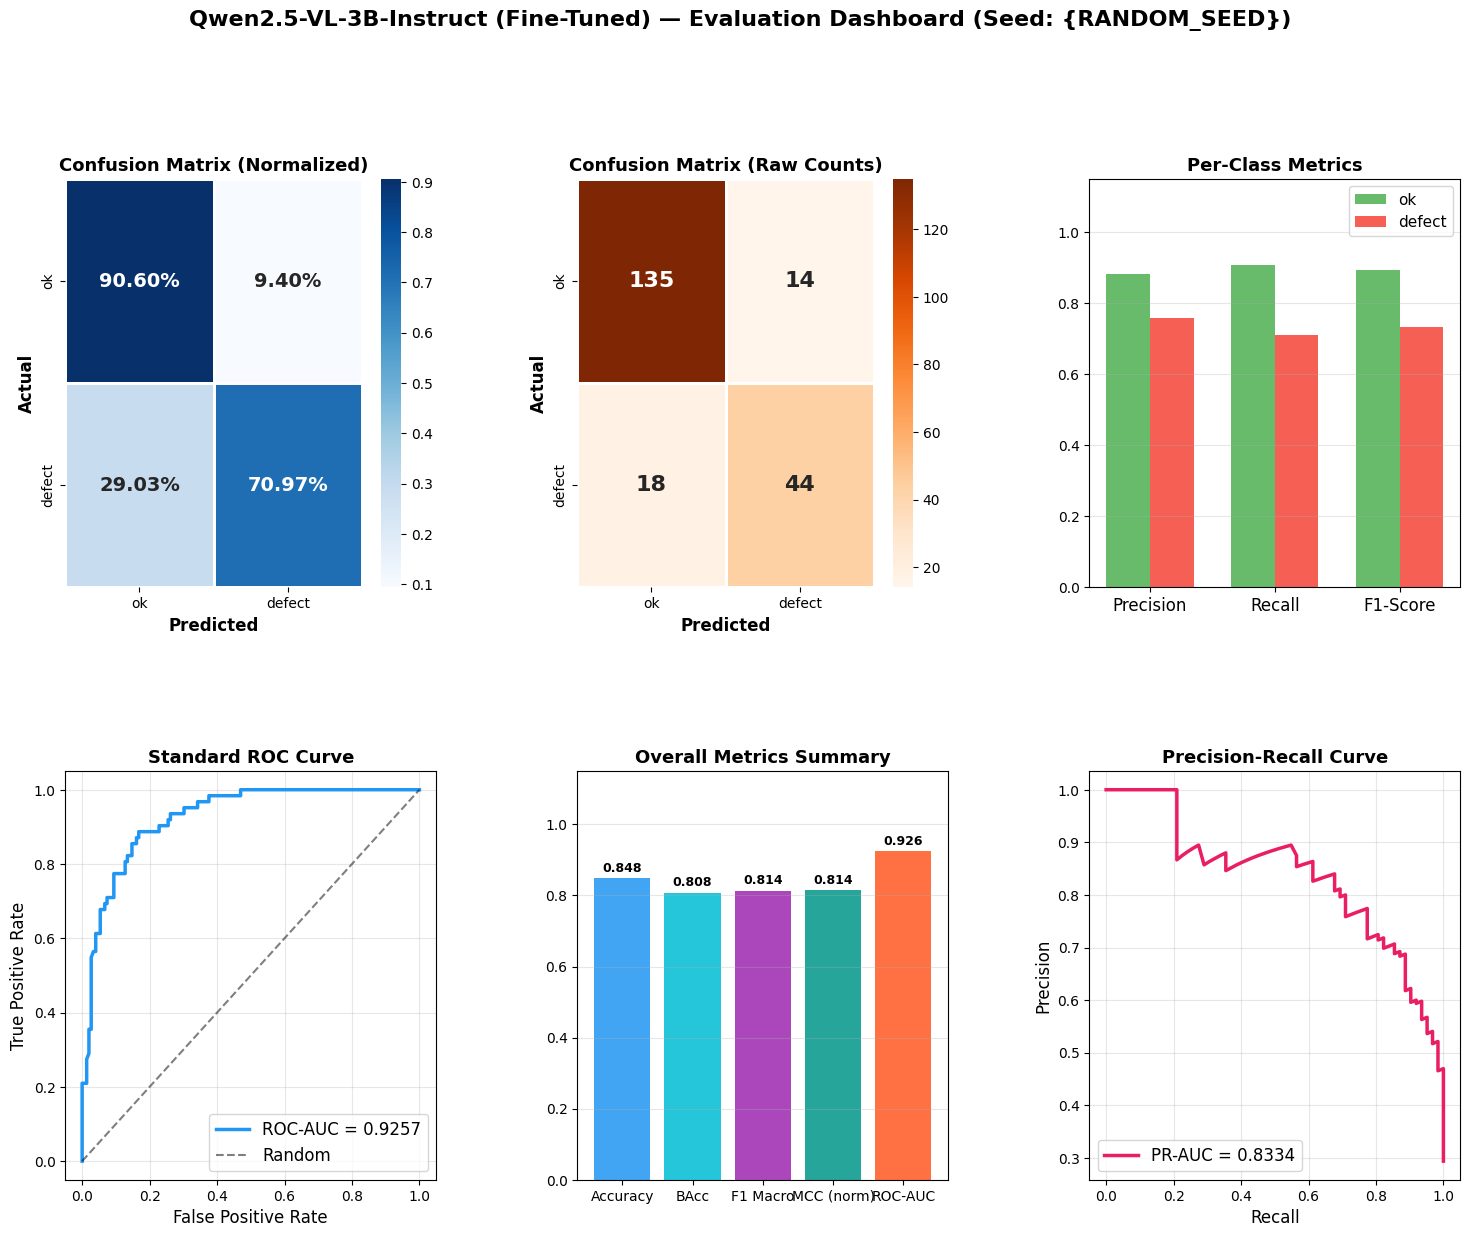

Dashboard saved: evaluation_dashboard_seed_456.png


In [15]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve, precision_recall_curve, auc as calc_auc, matthews_corrcoef
)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
import pandas as pd

label2int = {'ok': 0, 'defect': 1}
y_true_bin = [label2int[l] for l in y_true]
y_pred_bin = [label2int[l] for l in y_pred]
y_score    = y_scores

acc       = accuracy_score(y_true_bin, y_pred_bin)
bacc      = balanced_accuracy_score(y_true_bin, y_pred_bin)
prec_d    = precision_score(y_true_bin, y_pred_bin, pos_label=1)
rec_d     = recall_score(y_true_bin,    y_pred_bin, pos_label=1)
f1_d      = f1_score(y_true_bin,        y_pred_bin, pos_label=1)
prec_ok   = precision_score(y_true_bin, y_pred_bin, pos_label=0)
rec_ok    = recall_score(y_true_bin,    y_pred_bin, pos_label=0)
f1_ok     = f1_score(y_true_bin,        y_pred_bin, pos_label=0)
f1_macro  = f1_score(y_true_bin,        y_pred_bin, average='macro')
f1_weight = f1_score(y_true_bin,        y_pred_bin, average='weighted')
mcc       = matthews_corrcoef(y_true_bin, y_pred_bin)
cm        = confusion_matrix(y_true_bin, y_pred_bin)

try:
    roc_auc = roc_auc_score(y_true_bin, y_score)
    fpr, tpr, _ = roc_curve(y_true_bin, y_score)
except Exception as e:
    roc_auc = float('nan')

try:
    pr_prec, pr_rec, _ = precision_recall_curve(y_true_bin, y_score)
    pr_auc = calc_auc(pr_rec, pr_prec)
except Exception as e:
    pr_auc = float('nan')

print('=' * 58)
print('   EVALUATION REPORT — TEST SET (Seed: {RANDOM_SEED})')
print('=' * 58)
print(f'  Accuracy             : {acc:.4f}  ({acc*100:.2f}%)')
print(f'  Balanced Acc (BAcc)  : {bacc:.4f}')
print(f'  F1 (macro)           : {f1_macro:.4f}')
print(f'  F1 (weighted)        : {f1_weight:.4f}')
print(f'  MCC                  : {mcc:.4f}  (range: -1 ~ 1)')
print(f'  Standard ROC-AUC     : {roc_auc:.4f}')
print(f'  PR-AUC               : {pr_auc:.4f}')
print()
print('  Class: defect (Ambiguous)')
print(f'    Precision          : {prec_d:.4f}')
print(f'    Recall             : {rec_d:.4f}')
print(f'    F1-score           : {f1_d:.4f}')
print()
print('  Class: ok (Unambiguous)')
print(f'    Precision          : {prec_ok:.4f}')
print(f'    Recall             : {rec_ok:.4f}')
print(f'    F1-score           : {f1_ok:.4f}')
print('=' * 58)

fig = plt.figure(figsize=(18, 13))
gs  = gridspec.GridSpec(2, 3, hspace=0.45, wspace=0.38)

ax1 = fig.add_subplot(gs[0, 0])
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=['ok','defect'], yticklabels=['ok','defect'],
            ax=ax1, linewidths=1, annot_kws={'size': 14, 'weight': 'bold'})
ax1.set_xlabel('Predicted', fontsize=12, fontweight='bold')
ax1.set_ylabel('Actual', fontsize=12, fontweight='bold')
ax1.set_title('Confusion Matrix (Normalized)', fontsize=13, fontweight='bold')

ax2 = fig.add_subplot(gs[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['ok','defect'], yticklabels=['ok','defect'],
            ax=ax2, linewidths=1, annot_kws={'size': 16, 'weight': 'bold'})
ax2.set_xlabel('Predicted', fontsize=12, fontweight='bold')
ax2.set_ylabel('Actual', fontsize=12, fontweight='bold')
ax2.set_title('Confusion Matrix (Raw Counts)', fontsize=13, fontweight='bold')

ax3 = fig.add_subplot(gs[0, 2])
metrics_names = ['Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics_names))
w = 0.35
ax3.bar(x - w/2, [prec_ok, rec_ok, f1_ok], w, label='ok', color='#4CAF50', alpha=0.85)
ax3.bar(x + w/2, [prec_d,  rec_d,  f1_d],  w, label='defect', color='#F44336', alpha=0.85)
ax3.set_xticks(x)
ax3.set_xticklabels(metrics_names, fontsize=12)
ax3.set_ylim(0, 1.15)
ax3.set_title('Per-Class Metrics', fontsize=13, fontweight='bold')
ax3.legend(fontsize=11)
ax3.grid(axis='y', alpha=0.3)

ax4 = fig.add_subplot(gs[1, 0])
if not np.isnan(roc_auc):
    ax4.plot(fpr, tpr, color='#2196F3', lw=2.5, label=f'ROC-AUC = {roc_auc:.4f}')
ax4.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5, label='Random')
ax4.set_xlabel('False Positive Rate', fontsize=12)
ax4.set_ylabel('True Positive Rate', fontsize=12)
ax4.set_title('Standard ROC Curve', fontsize=13, fontweight='bold')
ax4.legend(fontsize=12, loc='lower right')
ax4.grid(True, alpha=0.3)

ax5 = fig.add_subplot(gs[1, 1])
summary_names = ['Accuracy', 'BAcc', 'F1 Macro', 'MCC (norm)', 'ROC-AUC']
mcc_norm = (mcc + 1) / 2
summary_scores = [acc, bacc, f1_macro, mcc_norm, roc_auc if not np.isnan(roc_auc) else 0]
bars = ax5.bar(summary_names, summary_scores, color=['#2196F3','#00BCD4','#9C27B0','#009688','#FF5722'], alpha=0.85)
for bar, score in zip(bars, summary_scores):
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{score:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax5.set_ylim(0, 1.15)
ax5.set_title('Overall Metrics Summary', fontsize=13, fontweight='bold')
ax5.grid(axis='y', alpha=0.3)

ax6 = fig.add_subplot(gs[1, 2])
if not np.isnan(pr_auc):
    ax6.plot(pr_rec, pr_prec, color='#E91E63', lw=2.5, label=f'PR-AUC = {pr_auc:.4f}')
ax6.set_xlabel('Recall', fontsize=12)
ax6.set_ylabel('Precision', fontsize=12)
ax6.set_title('Precision-Recall Curve', fontsize=13, fontweight='bold')
ax6.legend(fontsize=12, loc='lower left')
ax6.grid(True, alpha=0.3)

fig.suptitle('Qwen2.5-VL-3B-Instruct (Fine-Tuned) — Evaluation Dashboard (Seed: {RANDOM_SEED})', fontsize=16, fontweight='bold', y=1.01)
plt.savefig(f'evaluation_dashboard_seed_{RANDOM_SEED}.png', dpi=130, bbox_inches='tight')
plt.show()
print(f'Dashboard saved: evaluation_dashboard_seed_{RANDOM_SEED}.png')


## 11. Residual Error Analysis
Isolates False Positive and False Negative predictions for qualitative linguistic inspection.

In [16]:
import textwrap

errors = df_test[~df_test['correct']].copy()
fn = errors[(errors['defect'] == 'defect') & (errors['predicted'] == 'ok')]
fp = errors[(errors['defect'] == 'ok')     & (errors['predicted'] == 'defect')]

print('=' * 60)
print('         ERROR ANALYSIS')
print('=' * 60)
print(f'Total errors    : {len(errors)} / {len(df_test)} ({len(errors)/len(df_test)*100:.1f}%)')
print(f'False Negatives : {len(fn)}  (missed defects (higher severity risk))')
print(f'False Positives : {len(fp)}  (false alarms (ok classified as defect))')

print('\n--- 5 False Negatives (ground-truth defect, predicted ok) ---')
for i, (_, row) in enumerate(fn.head(5).iterrows()):
    print(f'\n[FN {i+1}] {textwrap.fill(row["requirement"], 70)}')

print('\n--- 5 False Positives (ground-truth ok, predicted defect) ---')
for i, (_, row) in enumerate(fp.head(5).iterrows()):
    print(f'\n[FP {i+1}] {textwrap.fill(row["requirement"], 70)}')

errors[['requirement','defect','predicted']].to_csv('error_analysis.csv', index=False)
print('\nSaved errors to: error_analysis.csv')


         ERROR ANALYSIS
Total errors    : 32 / 211 (15.2%)
False Negatives : 18  (missed defects (higher severity risk))
False Positives : 14  (false alarms (ok classified as defect))

--- 5 False Negatives (ground-truth defect, predicted ok) ---

[FN 1] If the failure is recoverable and an appropriate condition is met, the
LBC must continue to operate in the mode commanded via CAN.

[FN 2] If possible, it should be suitable to be mounted on stadard radar
samples without additional special modification of the samples.

[FN 3] This includes: No triangle may have an inner angle of less than five
degree, no short wire elements may be present.

[FN 4] The part number, the software version and where appropriate the
diagnostic information of a flashware are allocated in the first 128
byte of the first segment.

[FN 5] The backup battery is connected by a thick wire to the backup relay
and by two small sense wires to the ECU housing the PNM.

--- 5 False Positives (ground-truth ok, predicted 

## 12. Adapter Serialization and Results Export
Exports trained LoRA adapters, evaluation metrics, and prediction CSVs with seed indexing to support statistical significance aggregation.

In [17]:
import json

metrics_data = {
    'model': 'vlm_finetune',
    'seed': RANDOM_SEED,
    'accuracy': float(acc),
    'balanced_accuracy': float(bacc),
    'precision_defect': float(prec_d),
    'recall_defect': float(rec_d),
    'f1_defect': float(f1_d),
    'precision_ok': float(prec_ok),
    'recall_ok': float(rec_ok),
    'f1_ok': float(f1_ok),
    'f1_macro': float(f1_macro),
    'f1_weighted': float(f1_weight),
    'mcc': float(mcc),
    'roc_auc': float(roc_auc) if not np.isnan(roc_auc) else None,
    'pr_auc': float(pr_auc) if not np.isnan(pr_auc) else None,
    'confusion_matrix': cm.tolist(),
}

json_filename = f'metrics_vlm_finetune_seed_{RANDOM_SEED}.json'
csv_filename  = f'predictions_vlm_finetune_seed_{RANDOM_SEED}.csv'

with open(json_filename, 'w', encoding='utf-8') as f:
    json.dump(metrics_data, f, indent=2, ensure_ascii=False)

df_test.to_csv(csv_filename, index=False, encoding='utf-8')

print(f'Saved result files:')
print(f'   - Metrics JSON : {json_filename}')
print(f'   - Predictions  : {csv_filename}')


Saved result files:
   - Metrics JSON : metrics_vlm_finetune_seed_456.json
   - Predictions  : predictions_vlm_finetune_seed_456.csv


## 13. Qualitative Demonstration Routine
Interactive test harness for evaluating model predictions and posterior probability distributions on arbitrary requirement inputs.

In [18]:
TEST_CASES = [
    "The system shall handle multiple sessions quickly and provide adequate performance.",
    "All data should be validated before it is stored.",
    "The system shall respond to all API requests within 200 milliseconds under normal load.",
    "The login module shall authenticate users using SHA-256 hashed passwords stored in PostgreSQL.",
]

print('Demo Inference\n')
print('─' * 65)

for i, req in enumerate(TEST_CASES, 1):
    pred = predict(req)
    icon = '' if pred == 'defect' else '✅'
    print(f'[{i}] {icon} {pred}')
    print(f'     {req[:75]}...' if len(req) > 75 else f'     {req}')
    print()


Demo Inference

─────────────────────────────────────────────────────────────────
[1] ✅ ('defect', 0.9949396848678589)
     The system shall handle multiple sessions quickly and provide adequate perf...

[2] ✅ ('defect', 0.8333246111869812)
     All data should be validated before it is stored.

[3] ✅ ('ok', 0.002182716503739357)
     The system shall respond to all API requests within 200 milliseconds under ...

[4] ✅ ('ok', 0.020645931363105774)
     The login module shall authenticate users using SHA-256 hashed passwords st...

